# **1. Perkenalan Dataset**


Tahap pertama, Anda harus mencari dan menggunakan dataset dengan ketentuan sebagai berikut:

1. **Sumber Dataset**:  
   Dataset diperoleh dari Kaggle. Amazon Delivery dataset ini memberikan gambaran komprehensif tentang operasi logistik pengiriman tahap akhir perusahaan. Dataset ini mencakup lebih dari 43.632 pengiriman di berbagai kota, dengan informasi detail tentang rincian pesanan, agen pengiriman, kondisi cuaca dan lalu lintas, serta metrik kinerja pengiriman. Dataset ini memungkinkan peneliti dan analis untuk mengungkap wawasan tentang faktor-faktor yang memengaruhi efisiensi pengiriman, mengidentifikasi area untuk optimasi, dan mengeksplorasi dampak berbagai variabel terhadap pengalaman pelanggan secara keseluruhan.

2. **Link Dataset**:
   https://www.kaggle.com/datasets/sujalsuthar/amazon-delivery-dataset


# **2. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning atau deep learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# **3. Memuat Dataset**

Pada tahap ini, Anda perlu memuat dataset ke dalam notebook. Jika dataset dalam format CSV, Anda bisa menggunakan pustaka pandas untuk membacanya. Pastikan untuk mengecek beberapa baris awal dataset untuk memahami strukturnya dan memastikan data telah dimuat dengan benar.

Jika dataset berada di Google Drive, pastikan Anda menghubungkan Google Drive ke Colab terlebih dahulu. Setelah dataset berhasil dimuat, langkah berikutnya adalah memeriksa kesesuaian data dan siap untuk dianalisis lebih lanjut.

Jika dataset berupa unstructured data, silakan sesuaikan dengan format seperti kelas Machine Learning Pengembangan atau Machine Learning Terapan

In [2]:
df = pd.read_excel('amazon_delivery.xlsx')
df.head()

,Order_ID,Agent_Age,Agent_Rating,Store_Latitude,Store_Longitude,Drop_Latitude,Drop_Longitude,Order_Date,Order_Time,Pickup_Time,Weather,Traffic,Vehicle,Area,Delivery_Time,Category
0,ialx566343618,37,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Sunny,High,motorcycle,Urban,120,Clothing
1,akqg208421122,34,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Stormy,Jam,scooter,Metropolitian,165,Electronics
2,njpu434582536,23,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Sandstorms,Low,motorcycle,Urban,130,Sports
3,rjto796129700,38,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Sunny,Medium,motorcycle,Metropolitian,105,Cosmetics
4,zguw716275638,32,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Cloudy,High,scooter,Metropolitian,150,Toys


# **4. Exploratory Data Analysis (EDA)**

Pada tahap ini, Anda akan melakukan **Exploratory Data Analysis (EDA)** untuk memahami karakteristik dataset.

Tujuan dari EDA adalah untuk memperoleh wawasan awal yang mendalam mengenai data dan menentukan langkah selanjutnya dalam analisis atau pemodelan.

Missing Values:
: Order_ID            0
Agent_Age           0
Agent_Rating       54
Store_Latitude      0
Store_Longitude     0
Drop_Latitude       0
Drop_Longitude      0
Order_Date          0
Order_Time          0
Pickup_Time         0
Weather            91
Traffic             0
Vehicle             0
Area                0
Delivery_Time       0
Category            0
dtype: int64


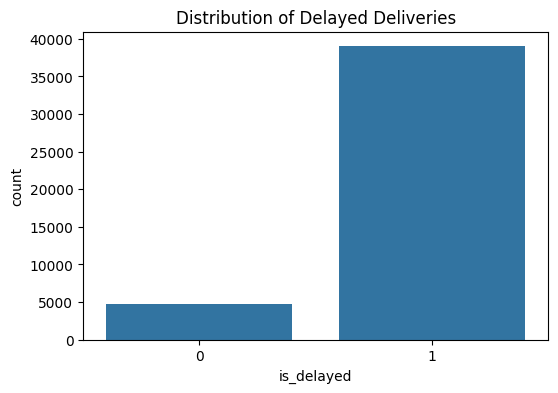

In [3]:
print("Missing Values:\n:", df.isnull().sum())

df['is_delayed'] = (df['Delivery_Time'] > 60).astype(int)

plt.figure(figsize=(6,4))
sns.countplot(x='is_delayed', data=df)
plt.title('Distribution of Delayed Deliveries')
plt.show()

# **5. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning.

Jika Anda menggunakan data teks, data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan yah. Khususnya ketika kami menggunakan data tidak terstruktur.

In [4]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

df_clean = df.dropna().copy()

features = ['Agent_Age', 'Weather', 'Traffic', 'Vehicle', 'is_delayed']
df_selected = df_clean[features].copy()

le = LabelEncoder()
categorical_cols = ['Weather', 'Traffic', 'Vehicle']
for col in categorical_cols:
    df_selected[col] = le.fit_transform(df_selected[col])

scaler = StandardScaler()
df_selected['Agent_Age'] = scaler.fit_transform(df_selected[['Agent_Age']])

print(df_selected.head())

   Agent_Age  Weather  Traffic  Vehicle  is_delayed
0   1.292270        4        0        0           1
1   0.771493        3        1        1           1
2  -1.138023        2        2        0           1
3   1.465863        4        3        0           1
4   0.424309        0        0        1           1
